# Preempting Hard Drive Failures: EDA & Preprocessing
Backblaze Drive Stats, Q1 + Q2 2026 (Jan 1 to Jun 30).

# 0. Get the data
The raw data is too big to submit (30 MB limit), so this cell downloads any missing quarter from Backblaze and unpacks its daily CSVs into `../data/raw`. The first run downloads about 3.4 GB and needs about 24 GB of disk; later runs skip it.

In [1]:
import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from pathlib import Path
from urllib.request import urlretrieve, urlcleanup
from zipfile import ZipFile

RAW = Path("../data/raw")
RAW.mkdir(parents=True, exist_ok=True)
for q, first_day in {"Q1": "2026-01-01", "Q2": "2026-04-01"}.items():
    if not (RAW / f"{first_day}.csv").exists():
        zip_path, _ = urlretrieve(f"https://f001.backblazeb2.com/file/Backblaze-Hard-Drive-Data/data_{q}_2026.zip")
        with ZipFile(zip_path) as z:
            for name in z.namelist():
                if name.endswith(".csv") and "__MACOSX" not in name:
                    (RAW / Path(name).name).write_bytes(z.read(name))
        urlcleanup()

len(list(RAW.glob("*.csv")))

181

# 1. Overview
Each row is one drive on one day. We count rows, columns, drives, the date range and failures over all daily files, show a few raw records, and rank drive models by failures. We keep the 3 models with the most failures: each model reports a different set of SMART attributes, so mixing many models would leave most columns empty.

In [2]:
con = duckdb.connect()
CSV = f"read_csv('{RAW}/*.csv', all_varchar=true, union_by_name=true)"

con.sql(f"""
    SELECT
        COUNT(*)                          AS total_rows,
        COUNT(DISTINCT serial_number)     AS drives,
        MIN(date)                         AS first_day,
        MAX(date)                         AS last_day,
        SUM(CAST(failure AS INTEGER))     AS failure_rows
    FROM {CSV}
""").df().assign(columns=len(con.sql(f"SELECT * FROM {CSV} LIMIT 0").columns))

,total_rows,drives,first_day,last_day,failure_rows,columns
0,62565487,363548,2026-01-01,2026-06-30,2552.0,197


In [3]:
con.sql(f"SELECT * FROM {CSV} LIMIT 5").df()

,date,serial_number,model,capacity_bytes,failure,datacenter,cluster_id,vault_id,pod_id,pod_slot_num,...,smart_250_normalized,smart_250_raw,smart_251_normalized,smart_251_raw,smart_252_normalized,smart_252_raw,smart_254_normalized,smart_254_raw,smart_255_normalized,smart_255_raw
0,2026-01-01,000a43e7dee60010,DELLBOSS VD,480036847616,0,ams5,031,2017,05,None,...,None,None,None,None,None,None,None,None,None,None
1,2026-01-01,00ac486b9bec0010,DELLBOSS VD,480036847616,0,ams5,031,2013,16,None,...,None,None,None,None,None,None,None,None,None,None
2,2026-01-01,01b776caeb6a0010,DELLBOSS VD,480036847616,0,ams5,031,2014,11,None,...,None,None,None,None,None,None,None,None,None,None
3,2026-01-01,02308a3415be0010,DELLBOSS VD,480036847616,0,ams5,031,2007,04,None,...,None,None,None,None,None,None,None,None,None,None
4,2026-01-01,0394cd7bc5d00010,DELLBOSS VD,480036847616,0,ams5,031,2017,04,None,...,None,None,None,None,None,None,None,None,None,None


In [4]:
models = con.sql(f"""
    SELECT model,
           COUNT(DISTINCT serial_number)  AS drives,
           SUM(CAST(failure AS INTEGER))  AS failures,
           ROUND(100.0 * failures / drives, 2) AS pct_failed
    FROM {CSV}
    GROUP BY model
    ORDER BY failures DESC
    LIMIT 10
""").df()

MODELS = list(models.model[:3])
models

,model,drives,failures,pct_failed
0,HGST HUH721212ALN604,9790,275.0,2.81
1,ST12000NM0008,18652,274.0,1.47
2,TOSHIBA MG07ACA14TA,37265,273.0,0.73
3,TOSHIBA MG08ACA16TA,40036,204.0,0.51
4,HGST HUH721212ALE604,13283,196.0,1.48
5,ST24000NM002H,9739,156.0,1.60
6,ST8000NM0055,13241,151.0,1.14
7,WDC WUH721816ALE6L4,26349,130.0,0.49
8,TOSHIBA MG10ACA20TE,25314,106.0,0.42
9,WDC WUH722222ALE6L4,45707,105.0,0.23


# 2. Uniform drive sample
The 3 models still have millions of rows, too many to plot in memory. We keep about 20% of drives, picked by a hash of the serial number. The same rule applies to failed and healthy drives, so the natural class imbalance is unchanged (compare `pct_failed` below), and each kept drive keeps its full history. Duplicate (drive, day) rows are dropped here, and the text columns are cast to proper types.

In [5]:
in_list = ", ".join(f"'{m}'" for m in MODELS)

con.sql(f"""
    COPY (
        SELECT
            CAST(date AS DATE)                 AS date,
            serial_number,
            model,
            TRY_CAST(capacity_bytes AS BIGINT) AS capacity_bytes,
            CAST(failure AS INTEGER)           AS failure,
            datacenter, cluster_id, vault_id, pod_id, pod_slot_num,
            TRY_CAST(COLUMNS('^smart_') AS DOUBLE)
        FROM {CSV}
        WHERE model IN ({in_list})
          AND hash(serial_number) % 100 < 20
        QUALIFY row_number() OVER (PARTITION BY serial_number, date) = 1
        ORDER BY serial_number, date
    ) TO '../data/sample.parquet' (FORMAT PARQUET)
""")

con.sql("DESCRIBE '../data/sample.parquet'").df()

,column_name,column_type,null,key,default,extra
0,date,DATE,YES,None,None,None
1,serial_number,VARCHAR,YES,None,None,None
2,model,VARCHAR,YES,None,None,None
3,capacity_bytes,BIGINT,YES,None,None,None
4,failure,INTEGER,YES,None,None,None
...,...,...,...,...,...,...
191,smart_252_raw,DOUBLE,YES,None,None,None
192,smart_254_normalized,DOUBLE,YES,None,None,None
193,smart_254_raw,DOUBLE,YES,None,None,None
194,smart_255_normalized,DOUBLE,YES,None,None,None


In [6]:
sample = con.sql("""
    SELECT model,
           COUNT(*)                       AS rows,
           COUNT(DISTINCT serial_number)  AS drives,
           SUM(failure)                   AS failures,
           ROUND(100.0 * failures / drives, 2) AS pct_failed
    FROM '../data/sample.parquet'
    GROUP BY model
""").df()

sample.merge(models[["model", "pct_failed"]], on="model", suffixes=("", "_all"))

,model,rows,drives,failures,pct_failed,pct_failed_all
0,ST12000NM0008,666385,3725,55.0,1.48,1.47
1,HGST HUH721212ALN604,352823,1996,58.0,2.91,2.81
2,TOSHIBA MG07ACA14TA,1342435,7455,56.0,0.75,0.73


# 3. Data quality
**Duplicates:** we count (drive, day) pairs that appear more than once in the raw data. Step 2 already kept only one row for each.

**Missing values:** the table shows how often each column is filled, per model (100 = always). Columns a model never reports are 0. Columns that are empty for all 3 models (`empty`) carry no information and are dropped in step 4. The other gaps are structural (that model doesn't report that attribute), so they stay as NaN for now and are imputed during preprocessing.

In [7]:
con.sql(f"""
    SELECT COUNT(*) AS duplicated_drive_days
    FROM (SELECT serial_number, date FROM {CSV} GROUP BY ALL HAVING COUNT(*) > 1)
""").df()

,duplicated_drive_days
0,0


In [8]:
fill = con.sql("""
    SELECT model, COUNT(*) AS n_rows, COUNT(COLUMNS(* EXCLUDE (model)))
    FROM '../data/sample.parquet'
    GROUP BY model
""").df().set_index("model")

pct = (fill.drop(columns="n_rows").div(fill["n_rows"], axis=0) * 100).round(0)
empty = list(pct.columns[(pct == 0).all()])
print(f"{len(empty)} empty columns dropped in step 4")
pct.T[(pct.T > 0).any(axis=1)]

116 empty columns dropped in step 4


model,HGST HUH721212ALN604,ST12000NM0008,TOSHIBA MG07ACA14TA
date,100.0,100.0,100.0
serial_number,100.0,100.0,100.0
capacity_bytes,100.0,100.0,100.0
failure,100.0,100.0,100.0
datacenter,100.0,100.0,100.0
...,...,...,...
smart_240_raw,0.0,100.0,100.0
smart_241_normalized,1.0,100.0,0.0
smart_241_raw,1.0,100.0,0.0
smart_242_normalized,1.0,100.0,0.0


# 4. Prediction labels
For each horizon h (3, 7 and 30 days), `label_{h}d` is 1 if the drive fails within the next h days, otherwise 0. It is NULL (unknown) when:
- the row's next h days run past the last day of data. A healthy drive's future is unknown there, so we blank these rows for every drive. Otherwise only failed drives would keep labels at the end and the labelled rows would be biased toward failures.
- the row comes after the drive's failure.

`days_to_failure` is kept for later steps. The asserts check that drives that never fail get no positive labels, and that each failed drive has at most h positive days.

In [9]:
HORIZONS = [3, 7, 30]

labels_sql = ",\n               ".join(f"""CASE WHEN date > last_day - {h - 1} THEN NULL
                   WHEN days_to_failure < 0 THEN NULL
                   WHEN days_to_failure < {h} THEN 1
                   ELSE 0 END AS label_{h}d""" for h in HORIZONS)

con.sql(f"""
    COPY (
        SELECT * EXCLUDE ({", ".join(["last_day"] + empty)}),
               {labels_sql}
        FROM (
            SELECT *,
                   date_diff('day', date, MIN(CASE WHEN failure = 1 THEN date END)
                                          OVER (PARTITION BY serial_number)) AS days_to_failure,
                   MAX(date) OVER () AS last_day
            FROM '../data/sample.parquet'
        )
        ORDER BY serial_number, date
    ) TO '../data/labeled.parquet' (FORMAT PARQUET)
""")

per_drive = con.sql("""
    SELECT MAX(failure) AS failed, SUM(COLUMNS('^label_'))
    FROM '../data/labeled.parquet'
    GROUP BY serial_number
""").df().fillna(0)
assert (per_drive.loc[per_drive.failed == 0, ["label_3d", "label_7d", "label_30d"]] == 0).all(axis=None)
assert all((per_drive[f"label_{h}d"] <= h).all() for h in HORIZONS)

con.sql("""
    SELECT month(date) AS month, COUNT(*) AS rows, SUM(COLUMNS('^label_'))
    FROM '../data/labeled.parquet'
    GROUP BY month
    ORDER BY month
""").df()

,month,rows,label_3d,label_7d,label_30d
0,1,406525,53.0,117.0,551.0
1,2,366890,45.0,105.0,536.0
2,3,405257,69.0,160.0,735.0
3,4,391578,109.0,244.0,1129.0
4,5,403005,88.0,178.0,707.0
5,6,388388,55.0,115.0,18.0


# 5. Univariate analysis
Distributions of the key SMART attributes, split by `label_30d` (does the drive fail within 30 days?):
- **Error counters** (5, 187, 188, 197, 198): almost always 0 with a very long tail, so they are plotted as log10(1 + value) with a log count axis. 187 and 188 are only reported by the Seagate model.
- **Power-on hours** (9) and **temperature** (194): plotted as is.

Histograms use density per class, so the 3,676 failing rows can be compared with the ~2M healthy ones. The table shows the share of rows where each counter is above 0.

In [10]:
COUNTERS = ["smart_5_raw", "smart_187_raw", "smart_188_raw", "smart_197_raw", "smart_198_raw"]
KEY = COUNTERS + ["smart_9_raw", "smart_194_raw"]
NAMES = {
    "smart_5_raw": "5: reallocated sectors",
    "smart_187_raw": "187: uncorrectable errors",
    "smart_188_raw": "188: command timeouts",
    "smart_197_raw": "197: pending sectors",
    "smart_198_raw": "198: offline uncorrectable",
    "smart_9_raw": "9: power-on hours",
    "smart_194_raw": "194: temperature (°C)",
}
COLORS = {0: "#2a78d6", 1: "#eb6834"}  # healthy, fails within 30 days

key = con.sql(f"""
    SELECT {", ".join(KEY)}, label_30d
    FROM '../data/labeled.parquet'
    WHERE label_30d IS NOT NULL
""").df()
key[COUNTERS] = np.log10(1 + key[COUNTERS])

(key[COUNTERS] > 0).groupby(key.label_30d).mean().mul(100).round(1)

,smart_5_raw,smart_187_raw,smart_188_raw,smart_197_raw,smart_198_raw
label_30d,,,,,
0,4.3,1.1,2.8,2.6,2.1
1,65.6,20.8,16.7,66.9,56.7


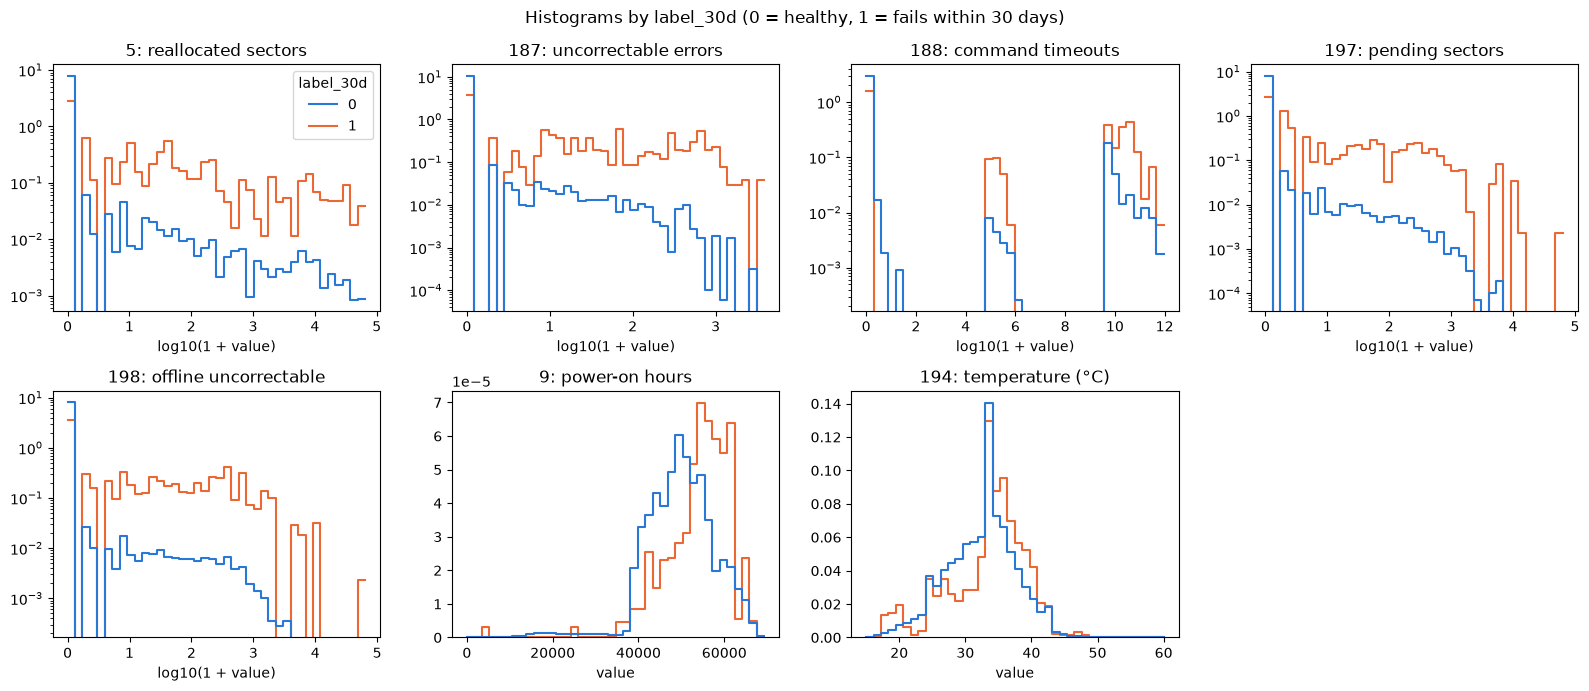

In [11]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.flat, KEY):
    sns.histplot(key, x=c, hue="label_30d", palette=COLORS, stat="density", common_norm=False,
                 element="step", fill=False, bins=40, legend=c == KEY[0], ax=ax)
    ax.set(title=NAMES[c], xlabel="log10(1 + value)" if c in COUNTERS else "value", ylabel="")
    if c in COUNTERS:
        ax.set_yscale("log")
axes.flat[-1].remove()
fig.suptitle("Histograms by label_30d (0 = healthy, 1 = fails within 30 days)")
fig.tight_layout()

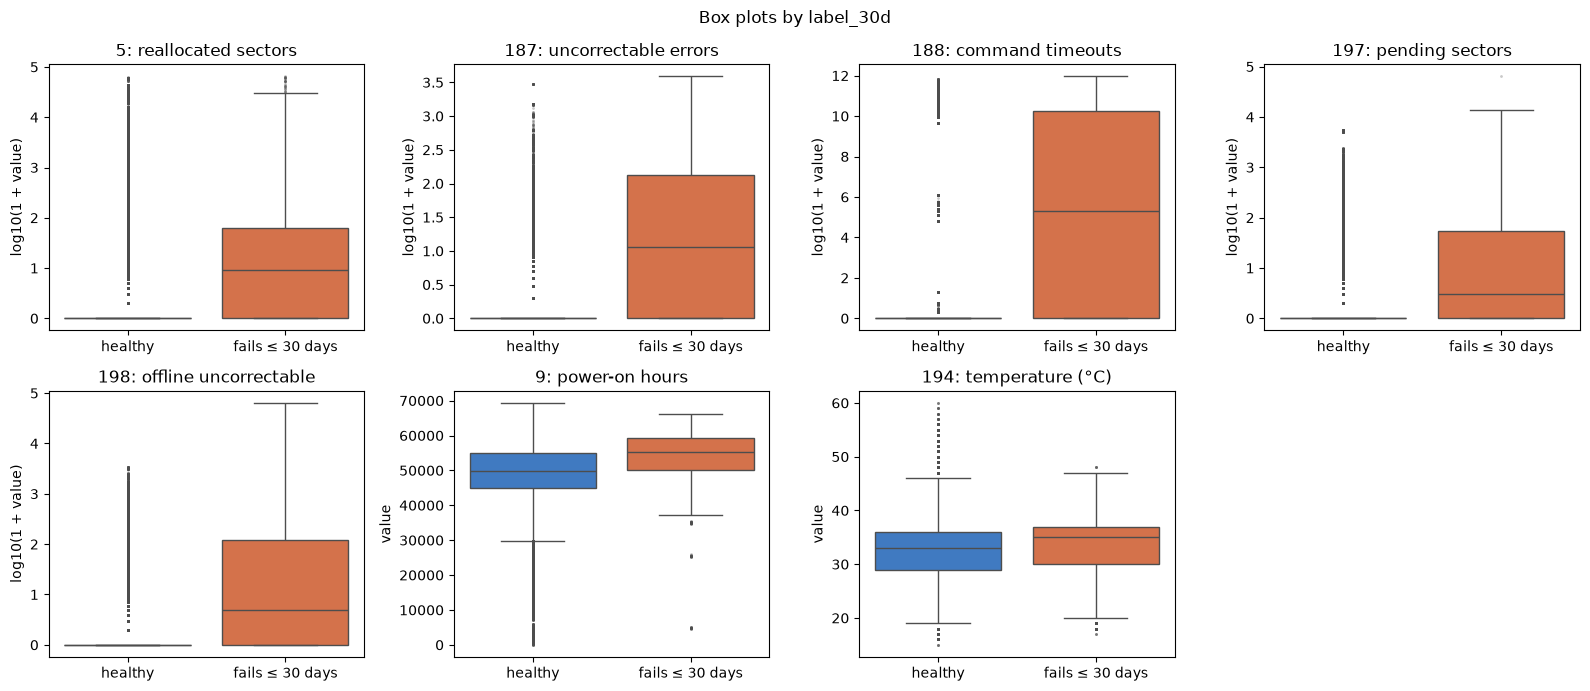

In [12]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.flat, KEY):
    sns.boxplot(key, x="label_30d", y=c, hue="label_30d", palette=COLORS, legend=False, ax=ax,
                flierprops={"marker": ".", "markersize": 2, "alpha": 0.3})
    ax.set(title=NAMES[c], xlabel="", ylabel="log10(1 + value)" if c in COUNTERS else "value")
    ax.set_xticks([0, 1], ["healthy", "fails ≤ 30 days"])
axes.flat[-1].remove()
fig.suptitle("Box plots by label_30d")
fig.tight_layout()

In [13]:
# Baseline rule from the proposal: flag a row if SMART 5, 197 or 198 is above 0
display(con.sql("""
    SELECT label_30d,
           ROUND(100 * AVG((smart_5_raw > 0 OR smart_197_raw > 0 OR smart_198_raw > 0)::INT), 1) AS pct_rows_flagged
    FROM '../data/labeled.parquet'
    WHERE label_30d IS NOT NULL
    GROUP BY label_30d
    ORDER BY label_30d
""").df())

# Same rule per drive: did the drive ever show one of these errors?
display(con.sql("""
    SELECT failed, COUNT(*) AS drives, ROUND(100 * AVG(ever_error::INT), 1) AS pct_drives_ever_flagged
    FROM (SELECT serial_number,
                 MAX(failure)                                                    AS failed,
                 MAX(smart_5_raw > 0 OR smart_197_raw > 0 OR smart_198_raw > 0)  AS ever_error
          FROM '../data/labeled.parquet'
          GROUP BY serial_number)
    GROUP BY failed
    ORDER BY failed
""").df())

# Age and temperature within each model
con.sql("""
    SELECT model, label_30d,
           MEDIAN(smart_9_raw)   AS median_power_on_hours,
           MEDIAN(smart_194_raw) AS median_temp_c
    FROM '../data/labeled.parquet'
    WHERE label_30d IS NOT NULL
    GROUP BY ALL
    ORDER BY ALL
""").df()

,label_30d,pct_rows_flagged
0,0,5.7
1,1,82.8


,failed,drives,pct_drives_ever_flagged
0,0,13007,6.2
1,1,169,89.3


,model,label_30d,median_power_on_hours,median_temp_c
0,HGST HUH721212ALN604,0,60635.0,35.0
1,HGST HUH721212ALN604,1,60142.0,36.0
2,ST12000NM0008,0,52626.0,32.0
3,ST12000NM0008,1,52857.5,33.0
4,TOSHIBA MG07ACA14TA,0,46650.0,32.0
5,TOSHIBA MG07ACA14TA,1,53638.0,35.0


**Takeaways (20% sample)**
- **The error counters carry the signal.** Flagging any row where SMART 5, 197 or 198 is above 0 catches 83% of rows within 30 days of a failure, but also 5.7% of healthy rows. The proposal's goal is a false-positive rate of at most 0.1%, so this rule is about 57× too noisy. About 6% of healthy drives carry old errors and keep running, so a rising counter probably matters more than a non-zero one. That points to change-over-time features.
- **About 1 in 9 failures is silent.** 89% of failed drives showed one of these errors at some point; the rest gave no SMART warning. This caps the recall any SMART-based model can reach.
- **Age is mostly a model effect.** Pooled, failing drives look older, but within HGST and Seagate the median age of failing and healthy drives is the same. HGST is the oldest model and has the highest failure rate, which creates the gap. Only Toshiba shows a real age effect.
- **Temperature effect is small but consistent:** failing drives run 1 to 3 °C hotter within every model.
- **SMART 188** on the Seagate model clusters around 10⁵ and 10¹⁰ rather than spreading out, which suggests several counters packed into one number. Treat it as above 0 or not, not as a magnitude.

# 6. Multivariate analysis
Correlation between every SMART raw attribute and the three labels. We use Spearman (rank) correlation because the attributes are heavily skewed and the relationships are not linear. Normalized columns are left out: each one is a vendor rescaling of its raw column. Constant columns are dropped because they have no correlation.

Correlations are computed pairwise over rows where both columns are filled, so attributes reported by only one model are compared within that model. White cells are pairs that no model reports together. Below the heatmap: the highly correlated pairs (|r| > 0.9), which are candidates to drop during feature selection, and the attributes most correlated with the labels.

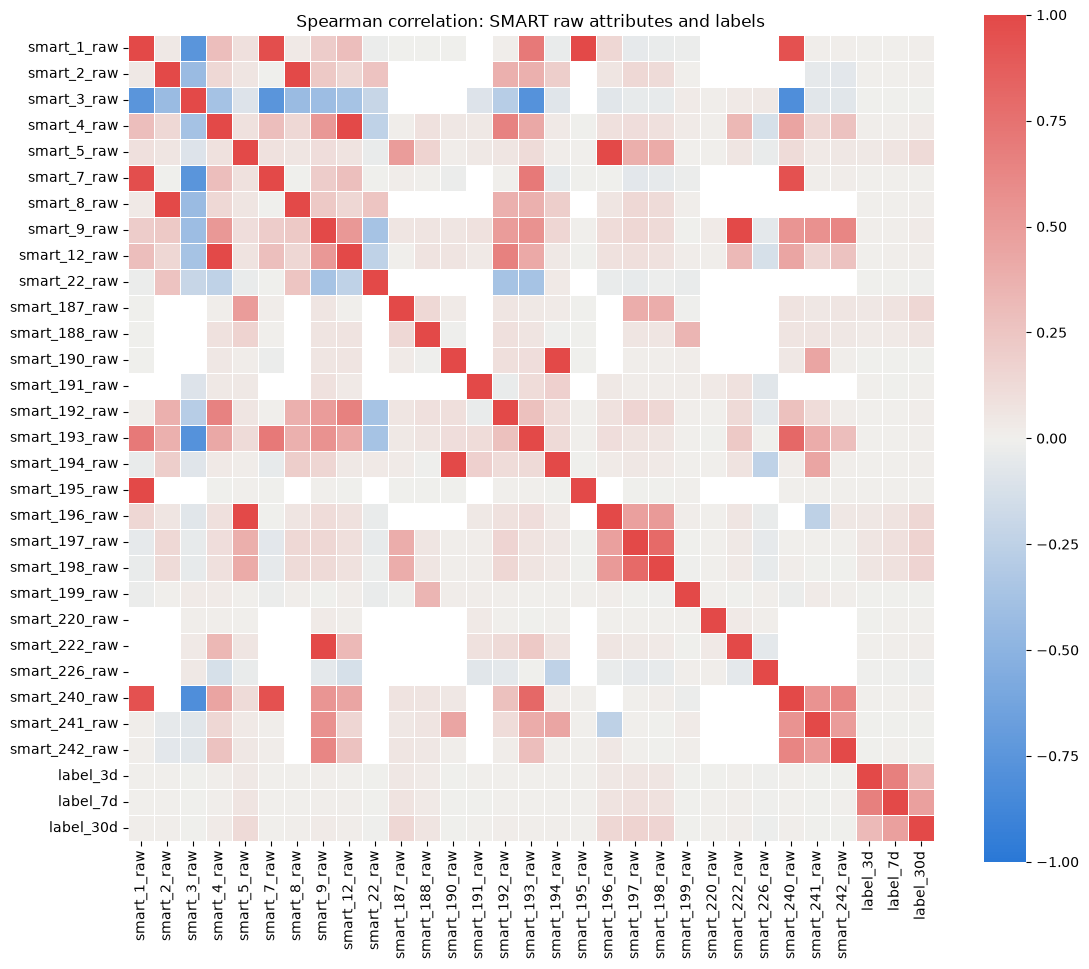

In [14]:
LABELS = ["label_3d", "label_7d", "label_30d"]
raw = [c for c in con.sql("SELECT * FROM '../data/labeled.parquet' LIMIT 0").columns if c.endswith("_raw")]

corr_df = con.sql(f"SELECT {', '.join(raw + LABELS)} FROM '../data/labeled.parquet'").df()
corr = corr_df.loc[:, corr_df.nunique() > 1].corr(method="spearman")

plt.figure(figsize=(13, 11))
sns.heatmap(corr, cmap=LinearSegmentedColormap.from_list("blue_red", ["#2a78d6", "#f0efec", "#e34948"]),
            vmin=-1, vmax=1, square=True, linewidths=0.5, linecolor="white")
plt.title("Spearman correlation: SMART raw attributes and labels");

In [15]:
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
display(pairs[pairs.abs() > 0.9].sort_values(key=abs, ascending=False).round(3).to_frame("spearman"))

corr[LABELS].drop(LABELS).sort_values("label_30d", key=abs, ascending=False).round(3).head(10)

,,spearman
smart_1_raw,smart_195_raw,1.000
smart_190_raw,smart_194_raw,1.000
smart_5_raw,smart_196_raw,1.000
smart_9_raw,smart_222_raw,1.000
smart_2_raw,smart_8_raw,0.998
smart_4_raw,smart_12_raw,0.995
smart_1_raw,smart_7_raw,0.962
smart_7_raw,smart_240_raw,0.948
smart_1_raw,smart_240_raw,0.948


,label_3d,label_7d,label_30d
smart_197_raw,0.061,0.088,0.171
smart_198_raw,0.055,0.080,0.162
smart_196_raw,0.052,0.074,0.145
smart_187_raw,0.053,0.075,0.144
smart_5_raw,0.046,0.065,0.130
smart_188_raw,0.027,0.037,0.069
smart_4_raw,0.009,0.013,0.026
smart_9_raw,0.008,0.012,0.025
smart_12_raw,0.007,0.011,0.023
smart_226_raw,-0.009,-0.013,-0.020


**Takeaways**
- **Duplicate columns** (correlation about 1): 5/196, 190/194 (temperature), 9/222 (power-on hours), 1/195, 2/8, 4/12. Each pair records the same thing, so keeping one of each is a first, easy feature-selection step.
- **Low correlations with the labels (at most 0.17) don't mean weak features.** Only about 0.2% of rows are positive, and with a label that rare a correlation can't get large. The flag rates in step 5 (83% vs 5.7%) show the real strength of the signal. For the same reason, the 3-day label's lower correlations come mostly from having fewer positive rows, not from being harder to predict.
- **Much of the structure reflects the models.** For example, SMART 3 against 1/7/240, and the white cells, come from which model reports which column. Adding `model` as a feature, or checking results per model, will separate the two.
- **Few independent failures.** The 3,676 positive 30-day rows come from only 168 failed drives, so there are far fewer independent examples than the row count suggests.